# Procesos estocásticos, estacionariedad, FAC y FACP

## Teoría y práctica con Python y datos del Banco Mundial

Este notebook utiliza dos series oficiales de Chile obtenidas mediante la API V2 del Banco Mundial:

- `NY.GDP.MKTP.KD`: PIB real, precios constantes de 2015 en US$.
- `NY.GDP.MKTP.KD.ZG`: crecimiento anual del PIB real, porcentaje.

La comparación es didácticamente útil: el nivel del PIB suele presentar tendencia, mientras que su crecimiento fluctúa alrededor de un nivel más estable.

### Paquetes requeridos

```bash
python -m pip install pandas numpy matplotlib requests scipy statsmodels
```

La API del Banco Mundial no requiere una clave de autenticación.

## 1. ¿Qué es un proceso estocástico?

Un proceso estocástico es una colección de variables aleatorias ordenadas mediante un índice:

$$\{X_t:t\in T\}$$

	X_t: representa una variable aleatoria en el instante t.
	T: es el conjunto de períodos de tiempo considerados (años, meses, días, trimestres, etc.).


En series de tiempo, $t$ representa el tiempo. Antes de observar la serie, cada $X_t$ es una variable aleatoria. Después de observarla, obtenemos una realización:

$$x_1,x_2,\ldots,x_n$$

Esta secuencia observada constituye la serie temporal que analizamos en la práctica.

Ejemplos económicos: inflación mensual, tipo de cambio diario, desempleo trimestral y PIB anual.

El objetivo no consiste solo en describir cada valor. También interesa comprender la dependencia entre $X_t$ y sus valores pasados.

In [28]:
# 1. Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.float_format', '{:,.3f}'.format)

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


## 2. Dos procesos simulados

### Ruido blanco

Un ruido blanco débil $\varepsilon_t$ satisface:

$$E(\varepsilon_t)=0,\qquad Var(\varepsilon_t)=\sigma^2,\qquad Cov(\varepsilon_t,\varepsilon_{t-k})=0\quad(k\neq0)$$

Sus observaciones pueden ser grandes o pequeñas, pero no presentan una estructura lineal predecible.

### Caminata aleatoria

$$X_t=X_{t-1}+\varepsilon_t$$

Los choques se acumulan. Por eso la caminata aleatoria no vuelve automáticamente a una media fija y no es estacionaria en nivel. Su primera diferencia sí es ruido blanco:

$$\Delta X_t=X_t-X_{t-1}=\varepsilon_t$$

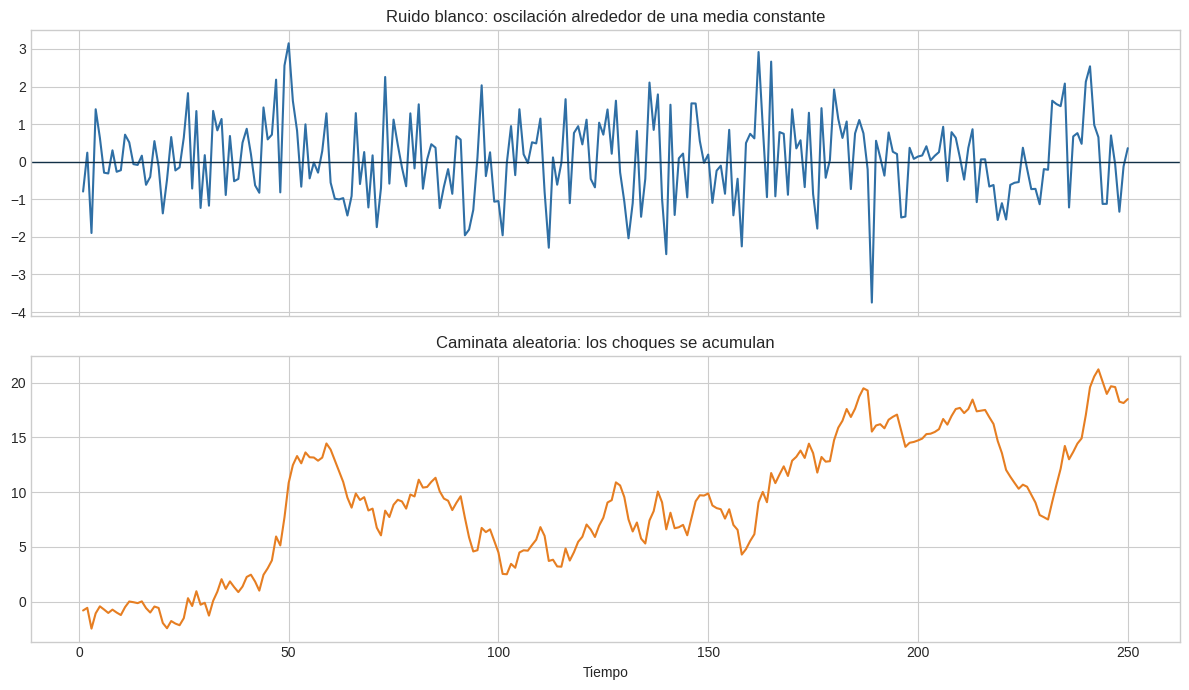

Media del ruido blanco: 0.074
Varianza del ruido blanco: 1.138
Media de la caminata: 8.898


In [29]:
# 2. Simulación reproducible
rng = np.random.default_rng(2026)
n = 250
ruido_blanco = rng.normal(loc=0, scale=1, size=n)
caminata_aleatoria = np.cumsum(ruido_blanco)
tiempo = np.arange(1, n + 1)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(tiempo, ruido_blanco, color='#2F6FA5')
axes[0].axhline(0, color='#123047', linewidth=1)
axes[0].set_title('Ruido blanco: oscilación alrededor de una media constante')
axes[1].plot(tiempo, caminata_aleatoria, color='#E67E22')
axes[1].set_title('Caminata aleatoria: los choques se acumulan')
axes[1].set_xlabel('Tiempo')
plt.tight_layout()
plt.show()

print('Media del ruido blanco:', round(ruido_blanco.mean(), 3))
print('Varianza del ruido blanco:', round(ruido_blanco.var(), 3))
print('Media de la caminata:', round(caminata_aleatoria.mean(), 3))

## 3. Estacionariedad estricta y débil

### Estacionariedad estricta

La distribución conjunta no cambia si todas las observaciones se desplazan la misma cantidad de tiempo:

$$F(X_{t_1},\ldots,X_{t_k})=F(X_{t_1+h},\ldots,X_{t_k+h})$$

Es una condición fuerte y difícil de verificar empíricamente.

### Estacionariedad débil o de segundo orden

Se requieren tres condiciones:

1. Media constante:
   $$E(X_t)=\mu$$
2. Varianza finita y constante:
   $$Var(X_t)=\sigma^2<\infty$$
3. Covarianza dependiente solo del rezago:
   $$Cov(X_t,X_{t-k})=\gamma_k$$

Una serie puede tener distribución no normal y aun así ser débilmente estacionaria. La normalidad y la estacionariedad son conceptos distintos.

## 4. Descarga desde la API del Banco Mundial

La consulta se realiza directamente contra `api.worldbank.org`. Se conservan únicamente observaciones no nulas y se ordenan cronológicamente.

La fecha final se deja abierta para que el notebook recupere la versión más reciente disponible cuando se ejecute nuevamente.

In [30]:
# 3. Serie 1: PIB real de Chile, nivel
url_nivel = 'https://api.worldbank.org/v2/country/CHL/indicator/NY.GDP.MKTP.KD'
params_nivel = {
    'format': 'json',
    'date': '1960:2030',
    'per_page': 200,
}

respuesta_nivel = requests.get(url_nivel, params=params_nivel, timeout=60)
respuesta_nivel.raise_for_status()
json_nivel = respuesta_nivel.json()

if not isinstance(json_nivel, list) or len(json_nivel) < 2 or json_nivel[1] is None:
    raise RuntimeError('La API no devolvió el PIB real de Chile.')

datos_nivel = pd.DataFrame(json_nivel[1])[['date', 'value']]
datos_nivel.columns = ['anio', 'pib_real']
datos_nivel['anio'] = pd.to_numeric(datos_nivel['anio'], errors='coerce')
datos_nivel['pib_real'] = pd.to_numeric(datos_nivel['pib_real'], errors='coerce')
datos_nivel = datos_nivel.dropna().sort_values('anio')

# 4. Serie 2: crecimiento anual del PIB real
url_crecimiento = 'https://api.worldbank.org/v2/country/CHL/indicator/NY.GDP.MKTP.KD.ZG'
params_crecimiento = {
    'format': 'json',
    'date': '1960:2030',
    'per_page': 200,
}

respuesta_crecimiento = requests.get(
    url_crecimiento,
    params=params_crecimiento,
    timeout=60,
)
respuesta_crecimiento.raise_for_status()
json_crecimiento = respuesta_crecimiento.json()

if not isinstance(json_crecimiento, list) or len(json_crecimiento) < 2 or json_crecimiento[1] is None:
    raise RuntimeError('La API no devolvió el crecimiento del PIB de Chile.')

datos_crecimiento = pd.DataFrame(json_crecimiento[1])[['date', 'value']]
datos_crecimiento.columns = ['anio', 'crecimiento_pib']
datos_crecimiento['anio'] = pd.to_numeric(datos_crecimiento['anio'], errors='coerce')
datos_crecimiento['crecimiento_pib'] = pd.to_numeric(
    datos_crecimiento['crecimiento_pib'],
    errors='coerce',
)
datos_crecimiento = datos_crecimiento.dropna().sort_values('anio')

datos = pd.merge(datos_nivel, datos_crecimiento, on='anio', how='inner')
datos = datos.set_index('anio')

print('Primera observación:', datos.index.min())
print('Última observación:', datos.index.max())
print('Número de años:', len(datos))
print(datos.tail())

Primera observación: 1961
Última observación: 2025
Número de años: 65
                pib_real  crecimiento_pib
anio                                     
2021 273,483,125,955.671           11.337
2022 279,127,595,176.477            2.064
2023 281,017,358,307.658            0.677
2024 288,900,250,332.819            2.805
2025 296,005,043,455.575            2.459


## 5. Inspección gráfica de nivel y crecimiento

Se buscan señales incompatibles con la estacionariedad:

- tendencia en la media;
- cambio persistente de varianza;
- ciclos o quiebres prolongados;
- observaciones extremas;
- dependencia entre valores cercanos.

Una prueba estadística nunca reemplaza esta inspección inicial.

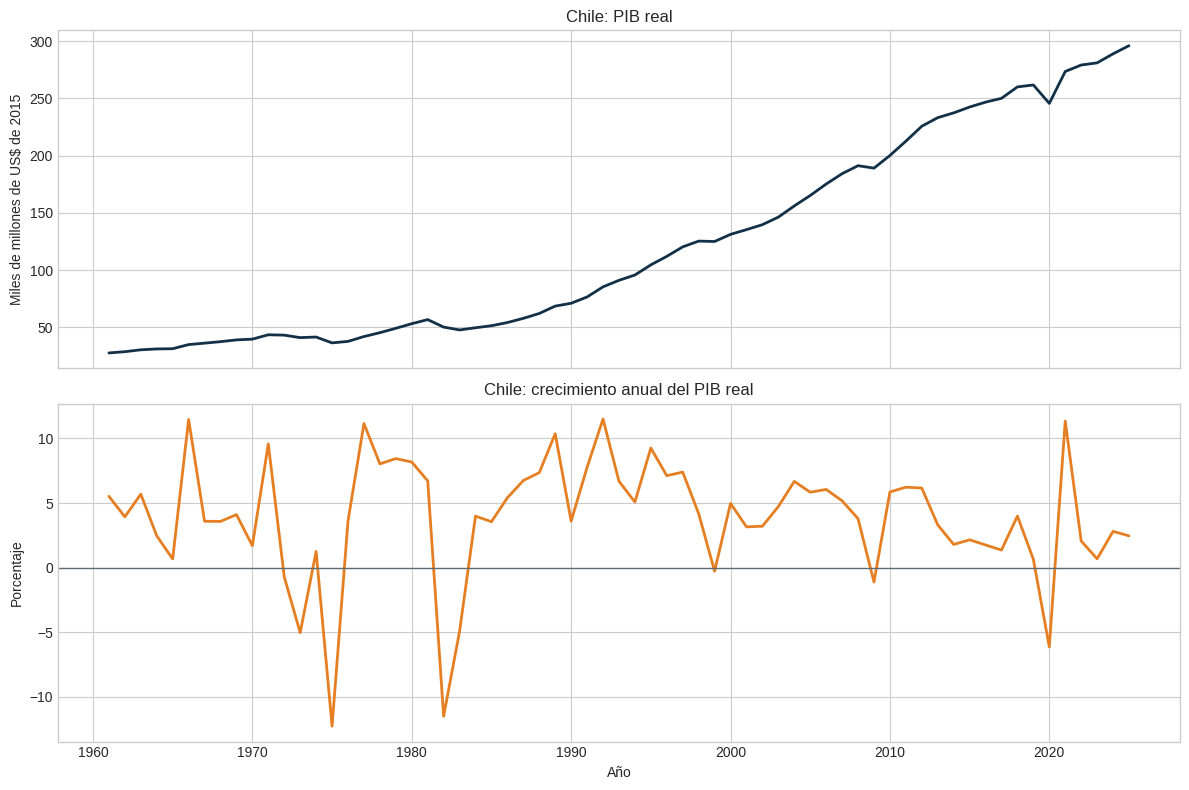

In [31]:
# 5. Gráficos de las series originales
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(datos.index, datos['pib_real'] / 1e9, color='#123047', linewidth=2)
axes[0].set_title('Chile: PIB real')
axes[0].set_ylabel('Miles de millones de US$ de 2015')

axes[1].plot(datos.index, datos['crecimiento_pib'], color='#E67E22', linewidth=2)
axes[1].axhline(0, color='#5D6B75', linewidth=1)
axes[1].set_title('Chile: crecimiento anual del PIB real')
axes[1].set_xlabel('Año')
axes[1].set_ylabel('Porcentaje')

plt.tight_layout()
plt.show()

## 6. Media y varianza móviles

Una forma visual de explorar la estacionariedad débil consiste en comparar estadísticas locales:

$$\bar X_t^{(w)}=\frac{1}{w}\sum_{j=0}^{w-1}X_{t-j}$$

Si la media o la varianza móvil cambian sistemáticamente, la hipótesis de estacionariedad resulta poco plausible. La ventana no produce una prueba formal; solo resume cambios locales.

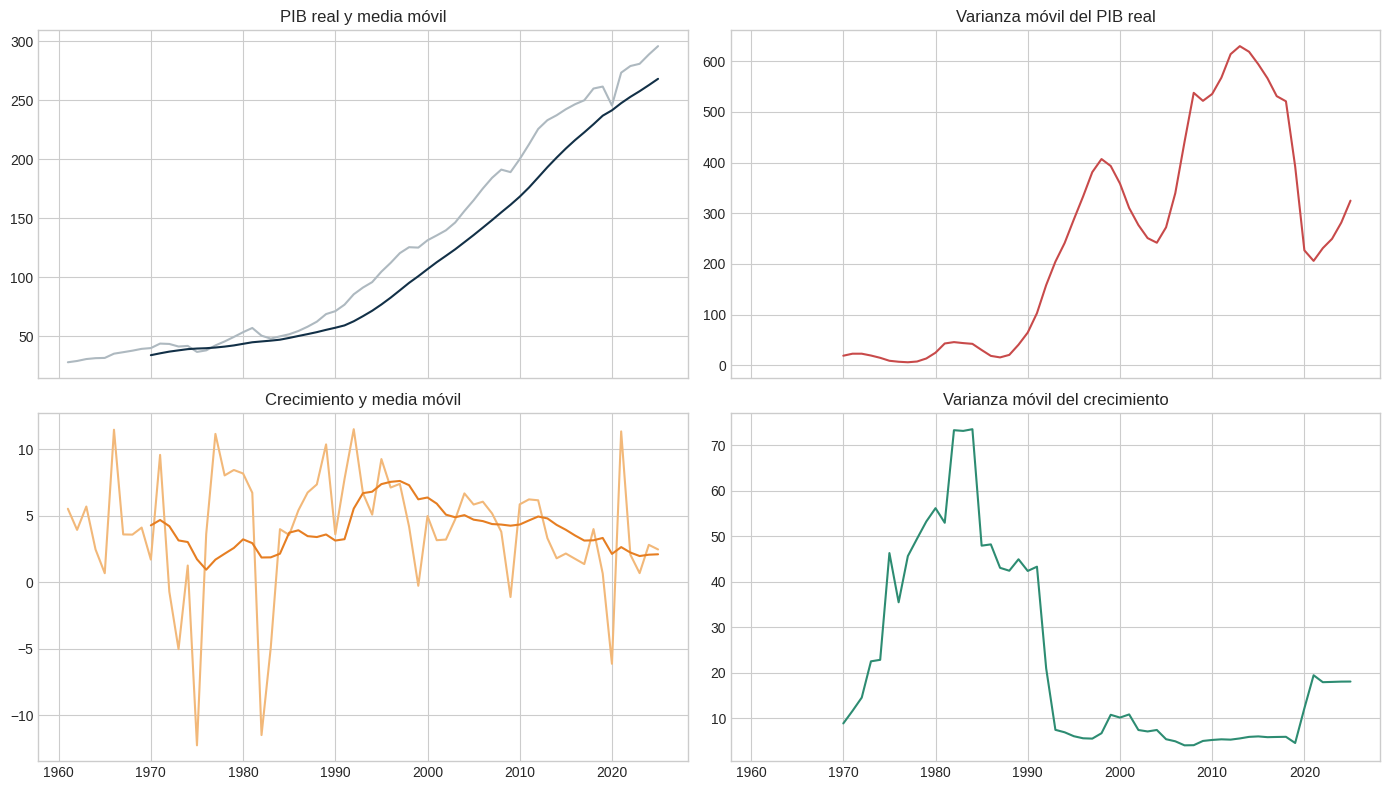

In [32]:
# 6. Estadísticas móviles de diez años
ventana = 10

datos['media_movil_nivel'] = datos['pib_real'].rolling(ventana).mean()
datos['var_movil_nivel'] = datos['pib_real'].rolling(ventana).var()
datos['media_movil_crecimiento'] = datos['crecimiento_pib'].rolling(ventana).mean()
datos['var_movil_crecimiento'] = datos['crecimiento_pib'].rolling(ventana).var()

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

axes[0, 0].plot(datos.index, datos['pib_real'] / 1e9, color='#AEB9C0')
axes[0, 0].plot(datos.index, datos['media_movil_nivel'] / 1e9, color='#123047')
axes[0, 0].set_title('PIB real y media móvil')

axes[0, 1].plot(datos.index, datos['var_movil_nivel'] / 1e18, color='#C84A4A')
axes[0, 1].set_title('Varianza móvil del PIB real')

axes[1, 0].plot(datos.index, datos['crecimiento_pib'], color='#F2B879')
axes[1, 0].plot(datos.index, datos['media_movil_crecimiento'], color='#E67E22')
axes[1, 0].set_title('Crecimiento y media móvil')

axes[1, 1].plot(datos.index, datos['var_movil_crecimiento'], color='#2D8C72')
axes[1, 1].set_title('Varianza móvil del crecimiento')

plt.tight_layout()
plt.show()

## 7. Transformación del nivel

El logaritmo convierte cambios proporcionales en diferencias aproximadamente aditivas. Para el PIB positivo:

$$g_t^{log}=100\,[\log(PIB_t)-\log(PIB_{t-1})]$$

Esta tasa logarítmica se aproxima al crecimiento porcentual publicado, aunque no coincide exactamente porque las definiciones y revisiones estadísticas pueden diferir.

Correlación entre ambas medidas: 0.9992
      crecimiento_pib  crecimiento_log
anio                                  
2021           11.337           10.740
2022            2.064            2.043
2023            0.677            0.675
2024            2.805            2.767
2025            2.459            2.430


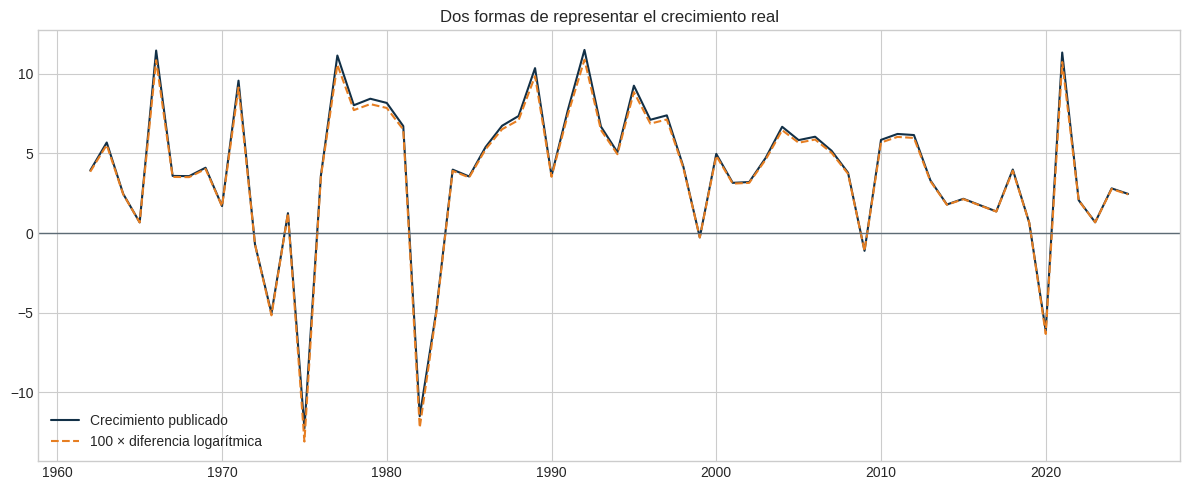

In [33]:
# 7. Logaritmo y primera diferencia logarítmica
datos['log_pib'] = np.log(datos['pib_real'])
datos['crecimiento_log'] = 100 * datos['log_pib'].diff()

comparacion_crecimiento = datos[
    ['crecimiento_pib', 'crecimiento_log']
].dropna()

correlacion_crecimientos = comparacion_crecimiento.corr().iloc[0, 1]

print('Correlación entre ambas medidas:', round(correlacion_crecimientos, 4))
print(comparacion_crecimiento.tail().round(3))

plt.figure(figsize=(12, 5))
plt.plot(
    comparacion_crecimiento.index,
    comparacion_crecimiento['crecimiento_pib'],
    label='Crecimiento publicado',
    color='#123047',
)
plt.plot(
    comparacion_crecimiento.index,
    comparacion_crecimiento['crecimiento_log'],
    label='100 × diferencia logarítmica',
    color='#E67E22',
    linestyle='--',
)
plt.axhline(0, color='#5D6B75', linewidth=1)
plt.title('Dos formas de representar el crecimiento real')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Función de autocorrelación, FAC

La autocorrelación muestral en el rezago $k$ es:

$$\widehat\rho_k=Corr(X_t,X_{t-k})$$

Lectura básica:

| Patrón de la FAC | Interpretación posible |
|---|---|
| Caída lenta desde valores altos | Tendencia o raíz unitaria |
| Corte después del rezago $q$ | Compatible con un proceso MA($q$) |
| Decaimiento gradual | Compatible con dependencia autorregresiva |
| Picos en $m,2m,3m$ | Estacionalidad de período $m$ |
| Barras pequeñas dentro de bandas | Compatible con baja dependencia lineal |

Las bandas son aproximadas. Una barra aislada puede aparecer por azar cuando se examinan muchos rezagos.

## 9. Función de autocorrelación parcial, FACP

La FACP en el rezago $k$ mide la relación entre $X_t$ y $X_{t-k}$ después de controlar los rezagos intermedios $1,\ldots,k-1$.

Lectura orientativa:

| Patrón de la FACP | Interpretación posible |
|---|---|
| Corte después del rezago $p$ | Compatible con AR($p$) |
| Decaimiento gradual | Compatible con un componente MA |
| Picos persistentes | Puede quedar tendencia, estacionalidad o estructura más compleja |

FAC y FACP ayudan a formular modelos candidatos. No determinan por sí solas el modelo definitivo.

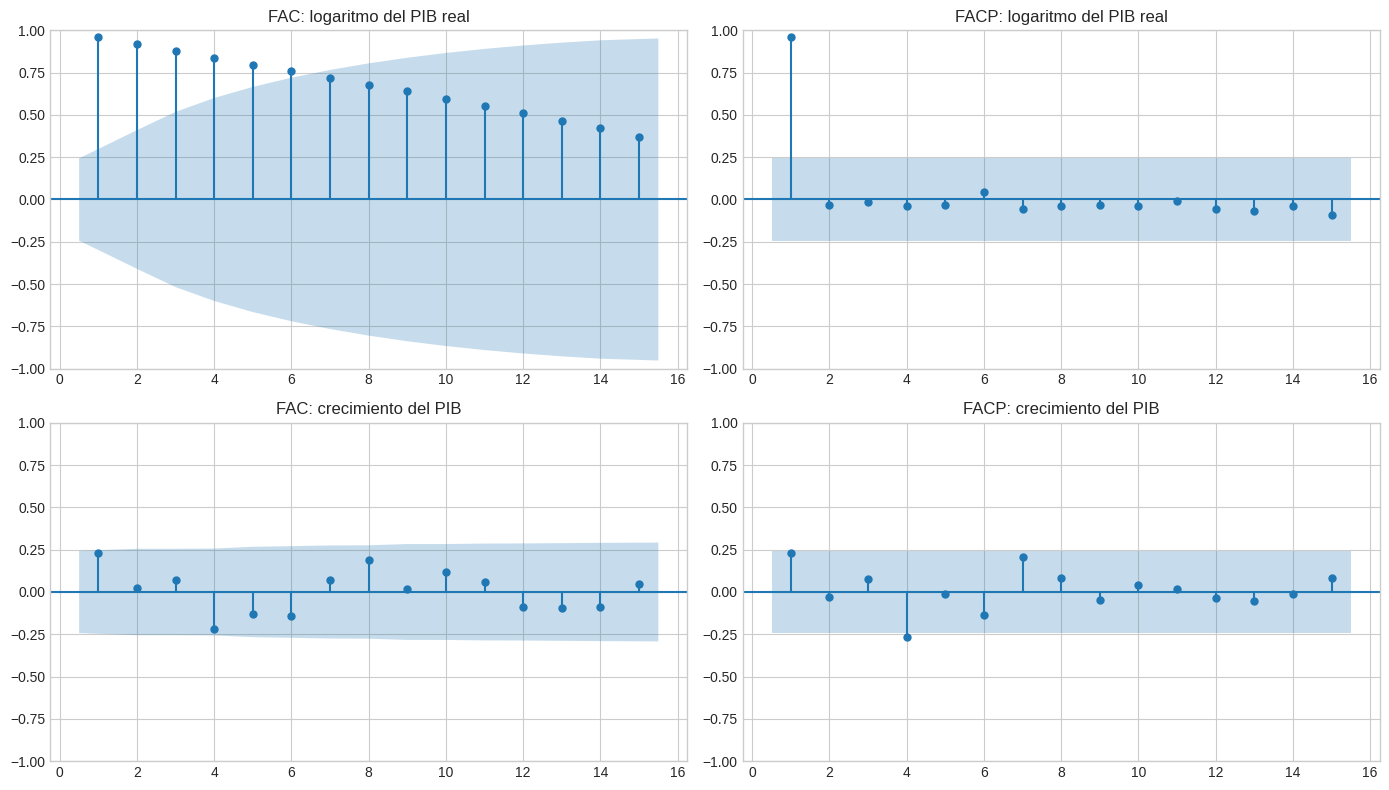

In [34]:
# 8. FAC y FACP del nivel y del crecimiento
serie_nivel = datos['log_pib'].dropna()
serie_crecimiento = datos['crecimiento_pib'].dropna()
max_lags = min(15, len(serie_crecimiento) // 2 - 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf(serie_nivel, lags=max_lags, ax=axes[0, 0], zero=False)
axes[0, 0].set_title('FAC: logaritmo del PIB real')

plot_pacf(
    serie_nivel,
    lags=max_lags,
    ax=axes[0, 1],
    zero=False,
    method='ywm',
)
axes[0, 1].set_title('FACP: logaritmo del PIB real')

plot_acf(serie_crecimiento, lags=max_lags, ax=axes[1, 0], zero=False)
axes[1, 0].set_title('FAC: crecimiento del PIB')

plot_pacf(
    serie_crecimiento,
    lags=max_lags,
    ax=axes[1, 1],
    zero=False,
    method='ywm',
)
axes[1, 1].set_title('FACP: crecimiento del PIB')

plt.tight_layout()
plt.show()

## 10. Dependencia gráfica mediante diagramas de rezago

Un diagrama de rezago representa $X_t$ frente a $X_{t-k}$:

- nube sin orientación: dependencia lineal débil;
- nube ascendente: autocorrelación positiva;
- nube descendente: autocorrelación negativa;
- forma curva: dependencia no lineal posible;
- grupos separados: quiebres, regímenes o atípicos.

La correlación resume asociación lineal; el gráfico puede mostrar patrones que el coeficiente oculta.

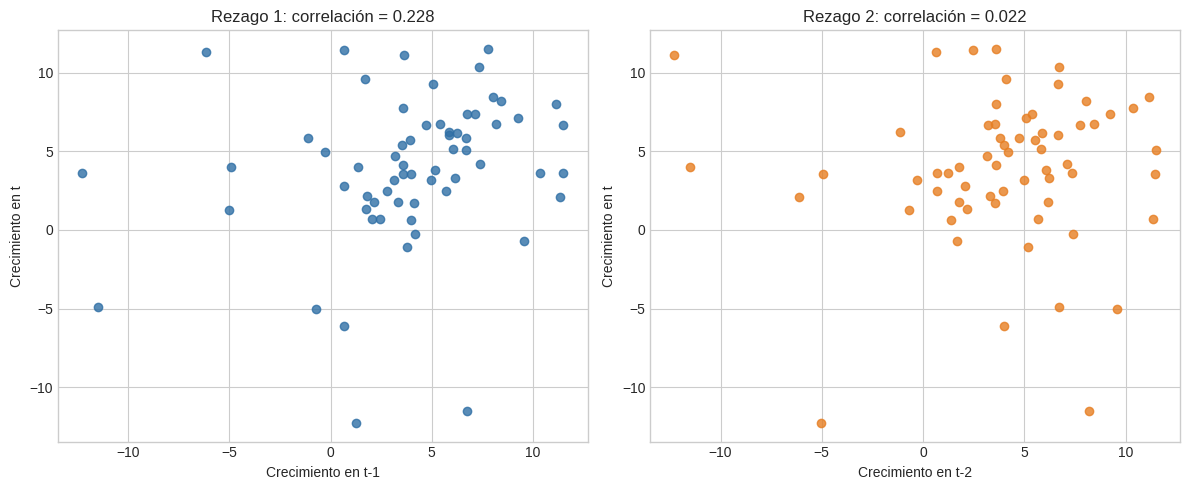

In [35]:
# 9. Diagramas de rezago para el crecimiento
dependencia = pd.DataFrame({'actual': serie_crecimiento})
dependencia['rezago_1'] = dependencia['actual'].shift(1)
dependencia['rezago_2'] = dependencia['actual'].shift(2)
dependencia = dependencia.dropna()

corr_lag1 = dependencia['actual'].corr(dependencia['rezago_1'])
corr_lag2 = dependencia['actual'].corr(dependencia['rezago_2'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    dependencia['rezago_1'],
    dependencia['actual'],
    color='#2F6FA5',
    alpha=0.8,
)
axes[0].set_title(f'Rezago 1: correlación = {corr_lag1:.3f}')
axes[0].set_xlabel('Crecimiento en t-1')
axes[0].set_ylabel('Crecimiento en t')

axes[1].scatter(
    dependencia['rezago_2'],
    dependencia['actual'],
    color='#E67E22',
    alpha=0.8,
)
axes[1].set_title(f'Rezago 2: correlación = {corr_lag2:.3f}')
axes[1].set_xlabel('Crecimiento en t-2')
axes[1].set_ylabel('Crecimiento en t')

plt.tight_layout()
plt.show()

## 11. Pruebas ADF y KPSS

Las pruebas plantean hipótesis nulas distintas:

### Dickey-Fuller aumentada, ADF

- $H_0$: existe raíz unitaria; la serie no es estacionaria.
- $H_1$: la serie es estacionaria alrededor de los componentes incluidos.

### KPSS

- $H_0$: la serie es estacionaria.
- $H_1$: la serie no es estacionaria.

Lectura conjunta:

| ADF | KPSS | Lectura |
|---|---|---|
| Rechaza $H_0$ | No rechaza $H_0$ | Evidencia favorable a estacionariedad |
| No rechaza $H_0$ | Rechaza $H_0$ | Evidencia favorable a no estacionariedad |
| Ambas rechazan | Resultado conflictivo; revisar quiebres y especificación |
| Ninguna rechaza | Evidencia insuficiente; revisar potencia y muestra |

La conclusión depende de si se incluye constante, tendencia y suficientes rezagos.

In [36]:
# 10. ADF y KPSS
adf_nivel = adfuller(serie_nivel, regression='ct', autolag='AIC')
kpss_nivel = kpss(serie_nivel, regression='ct', nlags='auto')

adf_crecimiento = adfuller(serie_crecimiento, regression='c', autolag='AIC')
kpss_crecimiento = kpss(serie_crecimiento, regression='c', nlags='auto')

pruebas = pd.DataFrame(
    {
        'ADF estadístico': [adf_nivel[0], adf_crecimiento[0]],
        'ADF p': [adf_nivel[1], adf_crecimiento[1]],
        'KPSS estadístico': [kpss_nivel[0], kpss_crecimiento[0]],
        'KPSS p': [kpss_nivel[1], kpss_crecimiento[1]],
    },
    index=['log(PIB real)', 'crecimiento del PIB'],
)

print(pruebas.round(4))
print('\nRegla con 5%:')
print('- ADF p < 0,05: rechazar raíz unitaria.')
print('- KPSS p < 0,05: rechazar estacionariedad.')

                     ADF estadístico  ADF p  KPSS estadístico  KPSS p
log(PIB real)                 -1.938  0.635             0.166   0.034
crecimiento del PIB           -6.243  0.000             0.105   0.100

Regla con 5%:
- ADF p < 0,05: rechazar raíz unitaria.
- KPSS p < 0,05: rechazar estacionariedad.


/tmp/ipykernel_1179/1888993785.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_nivel = adfuller(serie_nivel, regression='ct', autolag='AIC')
/tmp/ipykernel_1179/1888993785.py:3: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_nivel = kpss(serie_nivel, regression='ct', nlags='auto')
/tmp/ipykernel_1179/1888993785.py:5: Futu

## 12. ¿Cómo reconocer ruido blanco?

Una serie compatible con ruido blanco debería presentar:

- media aproximadamente constante;
- varianza estable;
- FAC sin autocorrelaciones sistemáticas;
- prueba de Ljung-Box sin evidencia conjunta de autocorrelación.

El estadístico de Ljung-Box es:

$$Q=n(n+2)\sum_{k=1}^{h}\frac{\widehat\rho_k^2}{n-k}$$

La hipótesis nula establece que las autocorrelaciones hasta $h$ son conjuntamente iguales a cero. Un valor $p$ mayor que 0,05 no demuestra independencia; solo indica que la prueba no detectó autocorrelación conjunta.

In [37]:
# 11. Comparación de Ljung-Box
ljung_ruido = acorr_ljungbox(
    ruido_blanco,
    lags=[10],
    return_df=True,
)

ljung_crecimiento = acorr_ljungbox(
    serie_crecimiento,
    lags=[10],
    return_df=True,
)

print('Ruido blanco simulado')
print(ljung_ruido.round(4))
print('\nCrecimiento del PIB de Chile')
print(ljung_crecimiento.round(4))

Ruido blanco simulado
    lb_stat  lb_pvalue
10   14.412      0.155

Crecimiento del PIB de Chile
    lb_stat  lb_pvalue
10   14.018      0.172


## 13. Práctica guiada

### Actividad 1: ruido blanco y caminata aleatoria

1. Cambie la semilla aleatoria.
2. Compare la FAC del ruido blanco y la caminata.
3. Diferencie la caminata y vuelva a graficar su FAC.
4. Explique por qué una trayectoria visualmente suave puede ser no estacionaria.

### Actividad 2: datos del Banco Mundial

1. Describa el PIB real y su crecimiento sin aplicar pruebas.
2. Compare media y varianza móviles.
3. Interprete los tres primeros rezagos de la FAC y la FACP.
4. Contraste ADF y KPSS.
5. Redacte una conclusión de máximo 150 palabras.

### Actividad 3: cambiar país

Reemplace `CHL` por `ARG`, `PER`, `COL`, `MEX` o `BRA`. Compare:

- años disponibles;
- volatilidad del crecimiento;
- resultados ADF y KPSS;
- forma de la FAC y FACP;
- observaciones extremas y posibles quiebres.

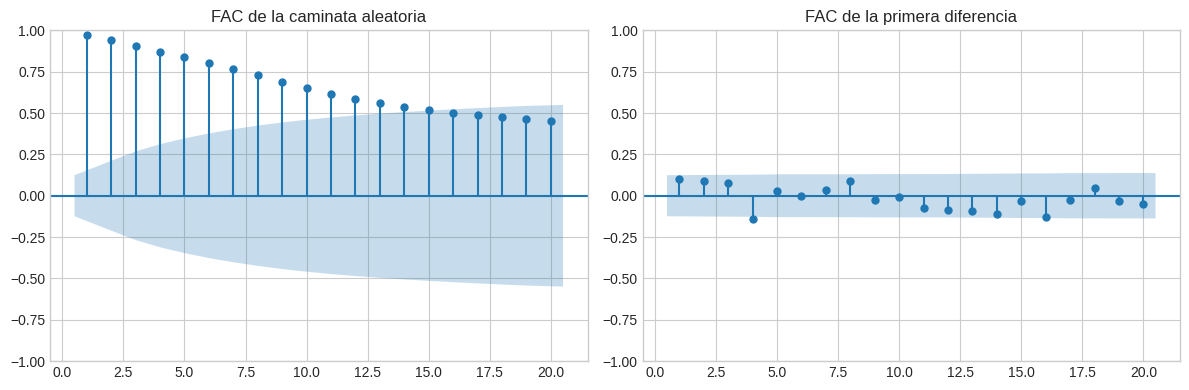

¿Coincide la diferencia con el ruido original? True


In [38]:
# 12. Ejercicio resuelto: diferenciar la caminata aleatoria
diferencia_caminata = np.diff(caminata_aleatoria)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(caminata_aleatoria, lags=20, ax=axes[0], zero=False)
axes[0].set_title('FAC de la caminata aleatoria')
plot_acf(diferencia_caminata, lags=20, ax=axes[1], zero=False)
axes[1].set_title('FAC de la primera diferencia')
plt.tight_layout()
plt.show()

print('¿Coincide la diferencia con el ruido original?',
      np.allclose(diferencia_caminata, ruido_blanco[1:]))

## 14. Plantilla para la conclusión técnica

> La serie en nivel presenta ________, por lo que la media parece ________. La FAC muestra ________. Las pruebas ADF y KPSS entregan ________. Después de aplicar ________, la serie muestra ________. Por tanto, para el modelamiento posterior se recomienda ________. Esta conclusión debe complementarse con la revisión de quiebres, atípicos y contexto económico.

## Bibliografía básica

- Box, G. E. P., Jenkins, G. M., Reinsel, G. C. y Ljung, G. M. *Time Series Analysis: Forecasting and Control*.
- Brockwell, P. J. y Davis, R. A. *Introduction to Time Series and Forecasting*.
- Hamilton, J. D. *Time Series Analysis*.
- Hyndman, R. J. y Athanasopoulos, G. *Forecasting: Principles and Practice*.
- Banco Mundial. Indicators API V2 y World Development Indicators.

### Enlaces oficiales

- API: https://api.worldbank.org/v2/
- Documentación: https://datahelpdesk.worldbank.org/knowledgebase/articles/889392
- PIB real: https://data.worldbank.org/indicator/NY.GDP.MKTP.KD
- Crecimiento del PIB: https://data.worldbank.org/indicator/NY.GDP.MKTP.KD.ZG

# Desarrollo de la práctica guiada

## Actividad 1: ruido blanco y caminata aleatoria

### 1. Cambie la semilla aleatoria.

Se usa la celda de simulación cambiando la semilla de `2026` a `42`.

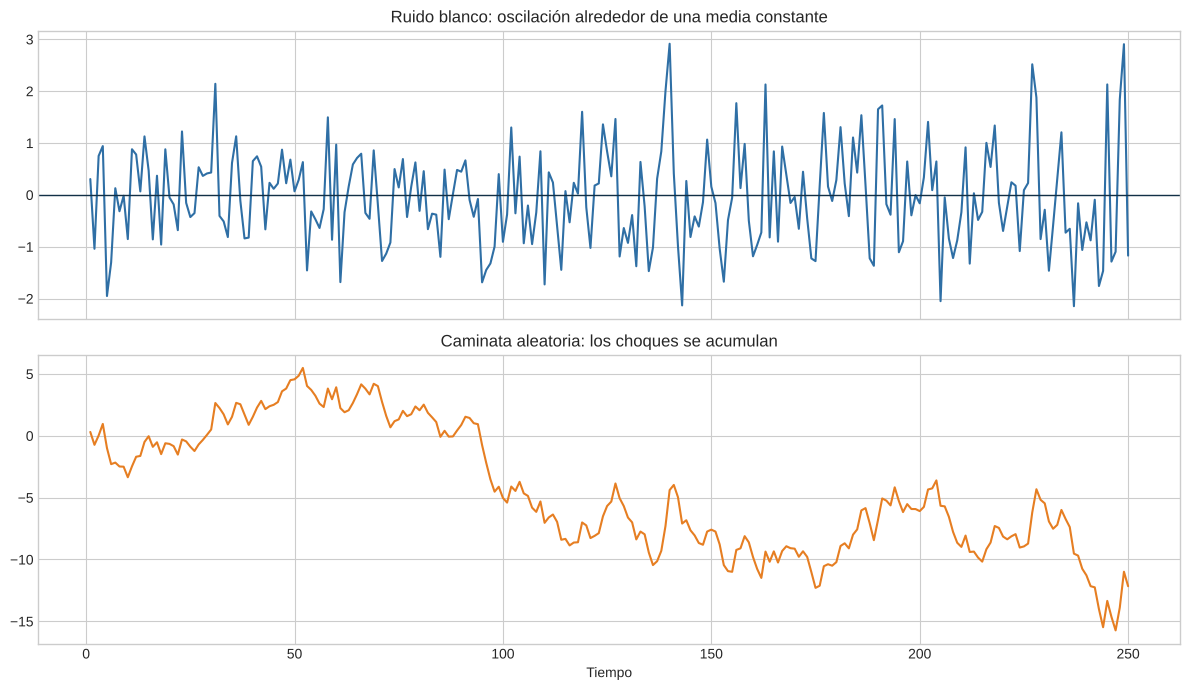

Media del ruido blanco: -0.049
Varianza del ruido blanco: 0.882
Media de la caminata: -4.455


In [ ]:
# 2. Simulación reproducible
rng = np.random.default_rng(42)
n = 250
ruido_blanco = rng.normal(loc=0, scale=1, size=n)
caminata_aleatoria = np.cumsum(ruido_blanco)
tiempo = np.arange(1, n + 1)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(tiempo, ruido_blanco, color='#2F6FA5')
axes[0].axhline(0, color='#123047', linewidth=1)
axes[0].set_title('Ruido blanco: oscilación alrededor de una media constante')
axes[1].plot(tiempo, caminata_aleatoria, color='#E67E22')
axes[1].set_title('Caminata aleatoria: los choques se acumulan')
axes[1].set_xlabel('Tiempo')
plt.tight_layout()
plt.show()

print('Media del ruido blanco:', round(ruido_blanco.mean(), 3))
print('Varianza del ruido blanco:', round(ruido_blanco.var(), 3))
print('Media de la caminata:', round(caminata_aleatoria.mean(), 3))

**Interpretación:**

Con la semilla 42 cambian todos los valores simulados, pero cada proceso se comporta igual que antes:

- El **ruido blanco** sigue oscilando alrededor de 0, con una dispersión parecida en todo el período. Su media (−0,049) y su varianza (0,882) están cerca de los valores teóricos 0 y 1, como ocurría con la semilla 2026 (0,074 y 1,138).
- La **caminata aleatoria** toma un camino completamente distinto. Con la semilla 2026 terminaba subiendo hasta ~21; con la semilla 42 sube hasta ~5 y luego baja hasta cerca de −16. Su media pasó de 8,898 a −4,455.

La caminata **no tiene una media fija** a la cual volver: su nivel depende de cómo se acumulan los choques. Por eso la media de una caminata no es un parámetro estable, mientras que la del ruido blanco sí lo es.

### 2. Compare la FAC del ruido blanco y la caminata.

Se usa el mismo formato del ejercicio resuelto (celda 12), con el ruido blanco y la caminata lado a lado.

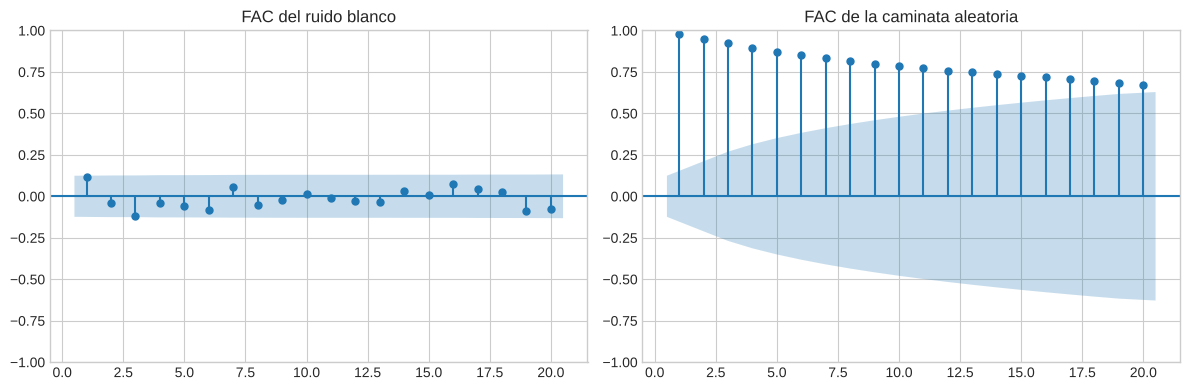

In [ ]:
# FAC del ruido blanco y de la caminata aleatoria
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(ruido_blanco, lags=20, ax=axes[0], zero=False)
axes[0].set_title('FAC del ruido blanco')
plot_acf(caminata_aleatoria, lags=20, ax=axes[1], zero=False)
axes[1].set_title('FAC de la caminata aleatoria')
plt.tight_layout()
plt.show()

**Interpretación:**

- **Ruido blanco:** las autocorrelaciones son pequeñas y quedan dentro de las bandas de confianza. Las de los rezagos 1 y 3 solo rozan el borde, algo esperable por azar al revisar 20 rezagos. No hay dependencia lineal entre un valor y sus valores pasados: es una serie **estacionaria y sin memoria**.
- **Caminata aleatoria:** la FAC parte cerca de 0,98 y **decae muy lentamente** (≈ 0,79 en el rezago 10 y ≈ 0,67 en el rezago 20). Según la tabla de la sección 8, una "caída lenta desde valores altos" indica **tendencia o raíz unitaria**: la serie **no es estacionaria**.

La diferencia es clara: en el ruido blanco el pasado no informa sobre el presente, mientras que en la caminata cada valor depende fuertemente de todos los anteriores.

### 3. Diferencie la caminata y vuelva a graficar su FAC.

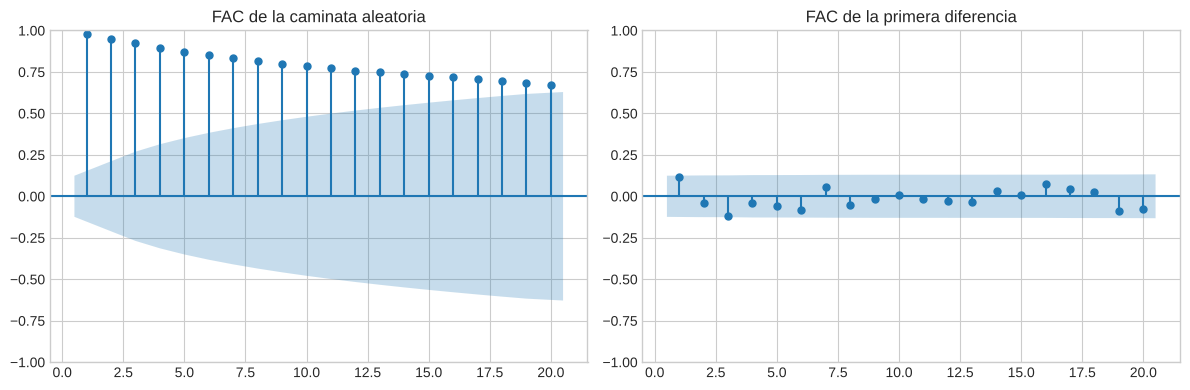

¿Coincide la diferencia con el ruido original? True


In [ ]:
# 12. Ejercicio resuelto: diferenciar la caminata aleatoria
diferencia_caminata = np.diff(caminata_aleatoria)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(caminata_aleatoria, lags=20, ax=axes[0], zero=False)
axes[0].set_title('FAC de la caminata aleatoria')
plot_acf(diferencia_caminata, lags=20, ax=axes[1], zero=False)
axes[1].set_title('FAC de la primera diferencia')
plt.tight_layout()
plt.show()

print('¿Coincide la diferencia con el ruido original?',
      np.allclose(diferencia_caminata, ruido_blanco[1:]))

**Interpretación:**

- Al diferenciar la caminata ($\Delta X_t = X_t - X_{t-1}$), su FAC cambia por completo. Pasa de barras altas que decaen lentamente a barras pequeñas **dentro de las bandas**, igual que la FAC del ruido blanco.
- La celda imprime `True`: la primera diferencia de la caminata **es exactamente el ruido blanco original**, porque $\Delta X_t = \varepsilon_t$.

La caminata aleatoria **no es estacionaria en nivel, pero su primera diferencia sí lo es**. Diferenciar elimina la acumulación de choques que provocaba la no estacionariedad.

### 4. Explique por qué una trayectoria visualmente suave puede ser no estacionaria.

**Respuesta:**

La caminata aleatoria se ve más suave que el ruido blanco porque cada valor es igual al anterior más un pequeño choque ($X_t = X_{t-1} + \varepsilon_t$). Valores consecutivos parecidos dan una línea sin saltos bruscos.

Esa suavidad viene de que la serie **acumula todos los choques pasados**. Como consecuencia:

- **no vuelve a una media fija**: puede alejarse indefinidamente hacia arriba o hacia abajo, como se vio al cambiar la semilla;
- **su varianza crece con el tiempo**, porque se suman cada vez más choques;
- **su FAC es cercana a 1** y decae lentamente.

La estacionariedad exige media y varianza constantes en el tiempo, y la caminata no cumple ninguna de las dos. Que una serie se vea "suave" solo indica mucha dependencia del pasado, no estabilidad.

## Actividad 2: datos del Banco Mundial (Chile)

Se descargan y preparan los datos con las mismas celdas de las secciones 4 a 11.

In [ ]:
# 3. Serie 1: PIB real de Chile, nivel
url_nivel = 'https://api.worldbank.org/v2/country/CHL/indicator/NY.GDP.MKTP.KD'
params_nivel = {
    'format': 'json',
    'date': '1960:2030',
    'per_page': 200,
}

respuesta_nivel = requests.get(url_nivel, params=params_nivel, timeout=60)
respuesta_nivel.raise_for_status()
json_nivel = respuesta_nivel.json()

if not isinstance(json_nivel, list) or len(json_nivel) < 2 or json_nivel[1] is None:
    raise RuntimeError('La API no devolvió el PIB real de Chile.')

datos_nivel = pd.DataFrame(json_nivel[1])[['date', 'value']]
datos_nivel.columns = ['anio', 'pib_real']
datos_nivel['anio'] = pd.to_numeric(datos_nivel['anio'], errors='coerce')
datos_nivel['pib_real'] = pd.to_numeric(datos_nivel['pib_real'], errors='coerce')
datos_nivel = datos_nivel.dropna().sort_values('anio')

# 4. Serie 2: crecimiento anual del PIB real
url_crecimiento = 'https://api.worldbank.org/v2/country/CHL/indicator/NY.GDP.MKTP.KD.ZG'
params_crecimiento = {
    'format': 'json',
    'date': '1960:2030',
    'per_page': 200,
}

respuesta_crecimiento = requests.get(
    url_crecimiento,
    params=params_crecimiento,
    timeout=60,
)
respuesta_crecimiento.raise_for_status()
json_crecimiento = respuesta_crecimiento.json()

if not isinstance(json_crecimiento, list) or len(json_crecimiento) < 2 or json_crecimiento[1] is None:
    raise RuntimeError('La API no devolvió el crecimiento del PIB de Chile.')

datos_crecimiento = pd.DataFrame(json_crecimiento[1])[['date', 'value']]
datos_crecimiento.columns = ['anio', 'crecimiento_pib']
datos_crecimiento['anio'] = pd.to_numeric(datos_crecimiento['anio'], errors='coerce')
datos_crecimiento['crecimiento_pib'] = pd.to_numeric(
    datos_crecimiento['crecimiento_pib'],
    errors='coerce',
)
datos_crecimiento = datos_crecimiento.dropna().sort_values('anio')

datos = pd.merge(datos_nivel, datos_crecimiento, on='anio', how='inner')
datos = datos.set_index('anio')

print('Primera observación:', datos.index.min())
print('Última observación:', datos.index.max())
print('Número de años:', len(datos))
print(datos.tail())

Primera observación: 1961
Última observación: 2025
Número de años: 65
                pib_real  crecimiento_pib
anio                                     
2021 273,483,125,955.671           11.337
2022 279,127,595,176.477            2.064
2023 281,017,358,307.658            0.677
2024 288,900,250,332.819            2.805
2025 296,005,043,455.575            2.459


**Datos:** 65 años, de 1961 a 2025. En 2025 el PIB real fue de unos 296 mil millones de US$ de 2015 y creció 2,46%.

### 1. Describa el PIB real y su crecimiento sin aplicar pruebas.

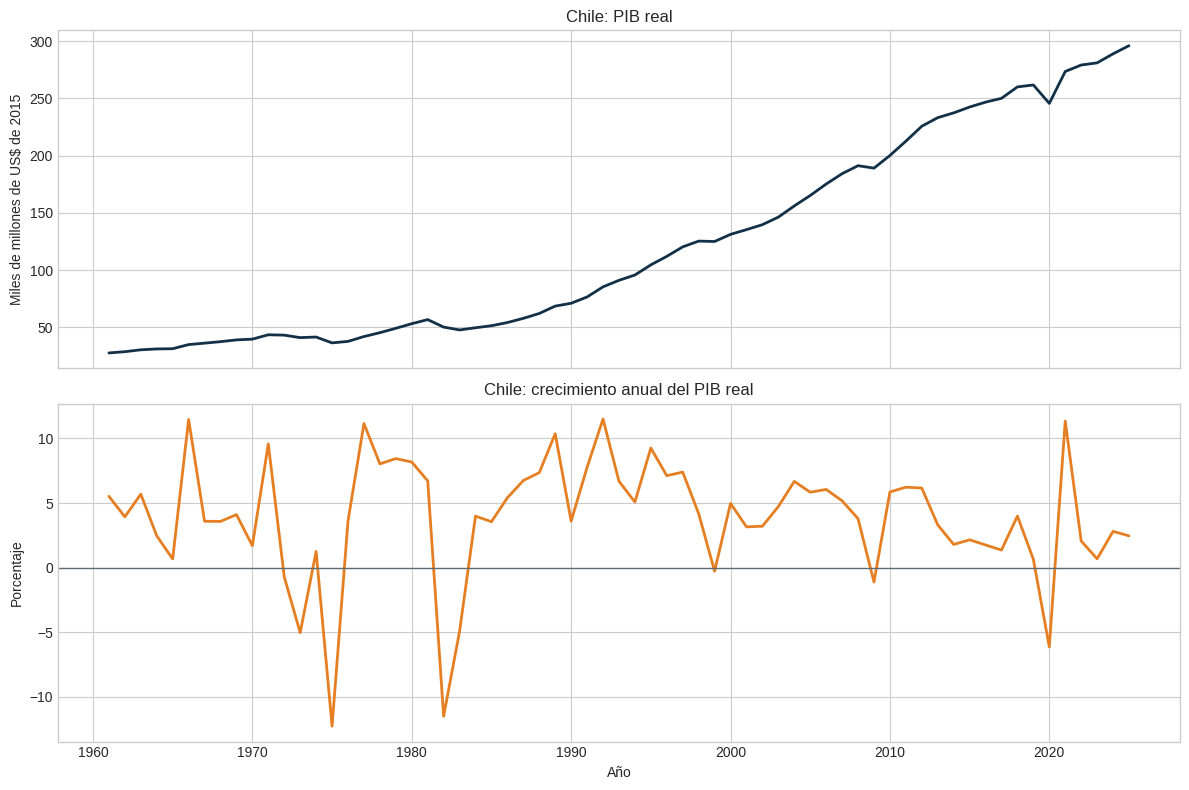

In [ ]:
# 5. Gráficos de las series originales
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(datos.index, datos['pib_real'] / 1e9, color='#123047', linewidth=2)
axes[0].set_title('Chile: PIB real')
axes[0].set_ylabel('Miles de millones de US$ de 2015')

axes[1].plot(datos.index, datos['crecimiento_pib'], color='#E67E22', linewidth=2)
axes[1].axhline(0, color='#5D6B75', linewidth=1)
axes[1].set_title('Chile: crecimiento anual del PIB real')
axes[1].set_xlabel('Año')
axes[1].set_ylabel('Porcentaje')

plt.tight_layout()
plt.show()

**Interpretación:**

- **PIB real:** crece de forma persistente, de unos 30 mil millones de US$ de 2015 en 1961 a cerca de 296 mil millones en 2025. Presenta una **tendencia creciente** que se acelera desde mediados de los años 80, con caídas puntuales en 1975, 1982-83, 2009 y 2020. Su media cambia en el tiempo, por lo que **no parece estacionario**.
- **Crecimiento del PIB:** oscila alrededor de un nivel cercano al 4%-5% anual, **sin tendencia**. Presenta **valores extremos** asociados a crisis: 1975 (≈ −12%), 1982 (≈ −11%), 2009 (≈ −1%) y 2020 (≈ −6%), además del rebote de 2021 (≈ +11%). Antes de 1990 las oscilaciones son mayores que después. Su media parece estable, por lo que **es candidato a ser estacionario**, aunque su volatilidad cambia entre períodos.

### 2. Compare media y varianza móviles.

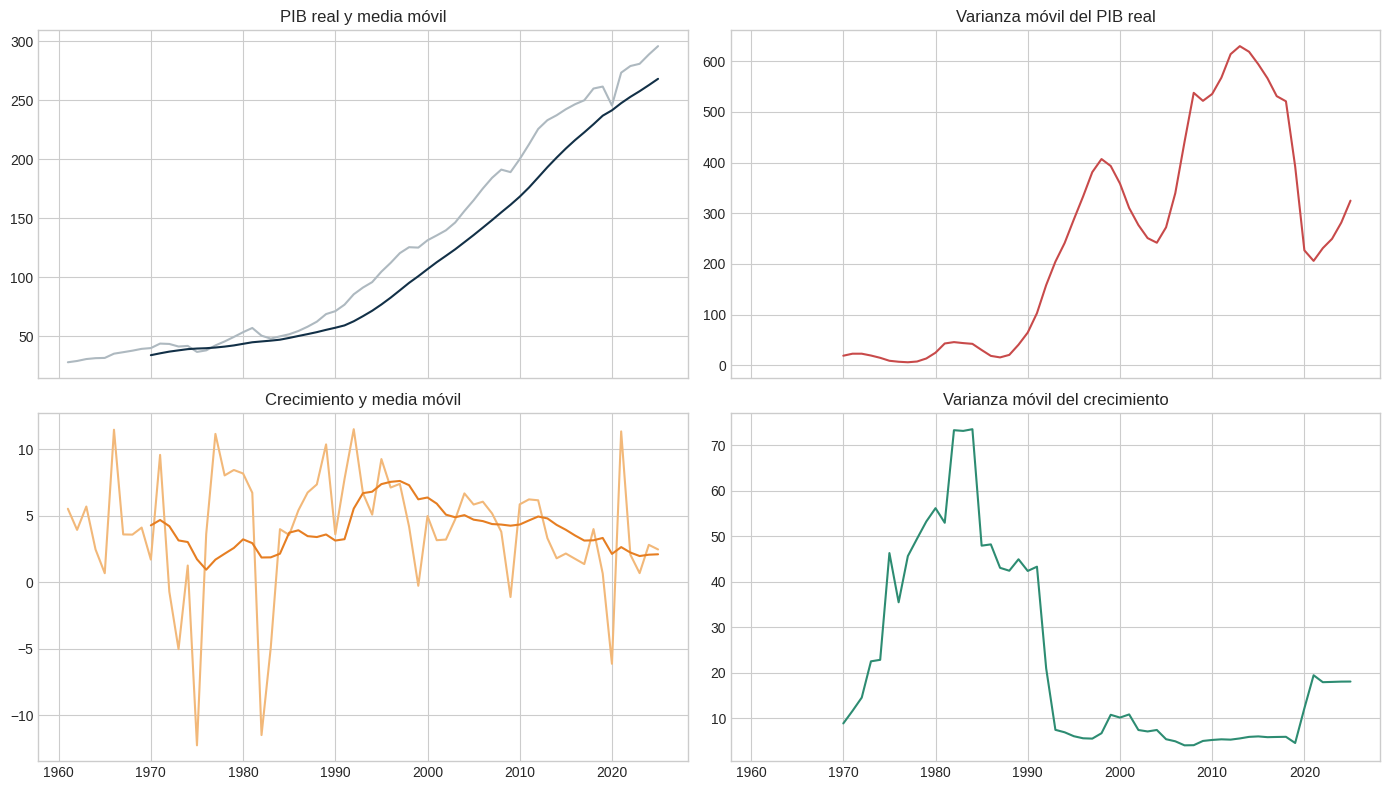

In [ ]:
# 6. Estadísticas móviles de diez años
ventana = 10

datos['media_movil_nivel'] = datos['pib_real'].rolling(ventana).mean()
datos['var_movil_nivel'] = datos['pib_real'].rolling(ventana).var()
datos['media_movil_crecimiento'] = datos['crecimiento_pib'].rolling(ventana).mean()
datos['var_movil_crecimiento'] = datos['crecimiento_pib'].rolling(ventana).var()

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

axes[0, 0].plot(datos.index, datos['pib_real'] / 1e9, color='#AEB9C0')
axes[0, 0].plot(datos.index, datos['media_movil_nivel'] / 1e9, color='#123047')
axes[0, 0].set_title('PIB real y media móvil')

axes[0, 1].plot(datos.index, datos['var_movil_nivel'] / 1e18, color='#C84A4A')
axes[0, 1].set_title('Varianza móvil del PIB real')

axes[1, 0].plot(datos.index, datos['crecimiento_pib'], color='#F2B879')
axes[1, 0].plot(datos.index, datos['media_movil_crecimiento'], color='#E67E22')
axes[1, 0].set_title('Crecimiento y media móvil')

axes[1, 1].plot(datos.index, datos['var_movil_crecimiento'], color='#2D8C72')
axes[1, 1].set_title('Varianza móvil del crecimiento')

plt.tight_layout()
plt.show()

**Interpretación** (ventana de 10 años):

| | Media móvil | Varianza móvil |
|---|---|---|
| **PIB real** | Aumenta durante todo el período | Casi nula hasta 1990; luego sube hasta ~400 y ~600 |
| **Crecimiento** | Se mueve entre ~1% y ~7,5%, sin tendencia persistente | Alta entre 1975 y 1992 (hasta ~73), baja entre 1993 y 2019 (~5) y sube en 2020-2021 (~18) |

- En el **PIB real**, la media y la varianza móviles cambian sistemáticamente. Eso incumple las condiciones de media y varianza constantes: **no es estacionario**.
- En el **crecimiento**, la media móvil se mantiene en un rango acotado, sin tendencia. La varianza móvil, en cambio, cambia por períodos: es alta en los años de las crisis de 1975 y 1982 y baja desde 1993. El crecimiento es **mucho más compatible con la estacionariedad** que el nivel, aunque con episodios de distinta volatilidad.

### 3. Interprete los tres primeros rezagos de la FAC y la FACP.

La celda de logaritmos es necesaria porque crea `log_pib`, que se usa en la FAC del nivel.

Correlación entre ambas medidas: 0.9992
      crecimiento_pib  crecimiento_log
anio                                  
2021           11.337           10.740
2022            2.064            2.043
2023            0.677            0.675
2024            2.805            2.767
2025            2.459            2.430


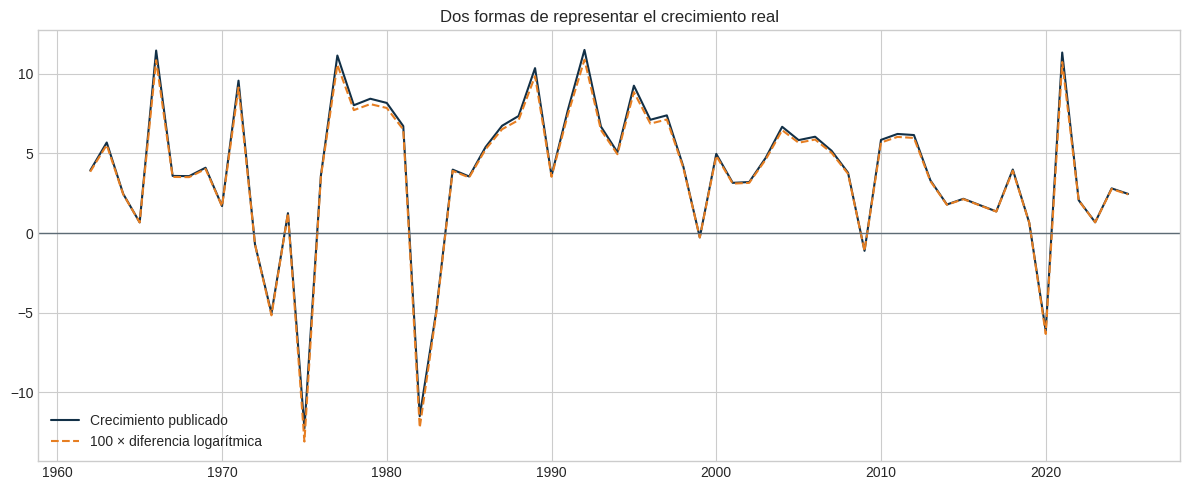

In [ ]:
# 7. Logaritmo y primera diferencia logarítmica
datos['log_pib'] = np.log(datos['pib_real'])
datos['crecimiento_log'] = 100 * datos['log_pib'].diff()

comparacion_crecimiento = datos[
    ['crecimiento_pib', 'crecimiento_log']
].dropna()

correlacion_crecimientos = comparacion_crecimiento.corr().iloc[0, 1]

print('Correlación entre ambas medidas:', round(correlacion_crecimientos, 4))
print(comparacion_crecimiento.tail().round(3))

plt.figure(figsize=(12, 5))
plt.plot(
    comparacion_crecimiento.index,
    comparacion_crecimiento['crecimiento_pib'],
    label='Crecimiento publicado',
    color='#123047',
)
plt.plot(
    comparacion_crecimiento.index,
    comparacion_crecimiento['crecimiento_log'],
    label='100 × diferencia logarítmica',
    color='#E67E22',
    linestyle='--',
)
plt.axhline(0, color='#5D6B75', linewidth=1)
plt.title('Dos formas de representar el crecimiento real')
plt.legend()
plt.tight_layout()
plt.show()

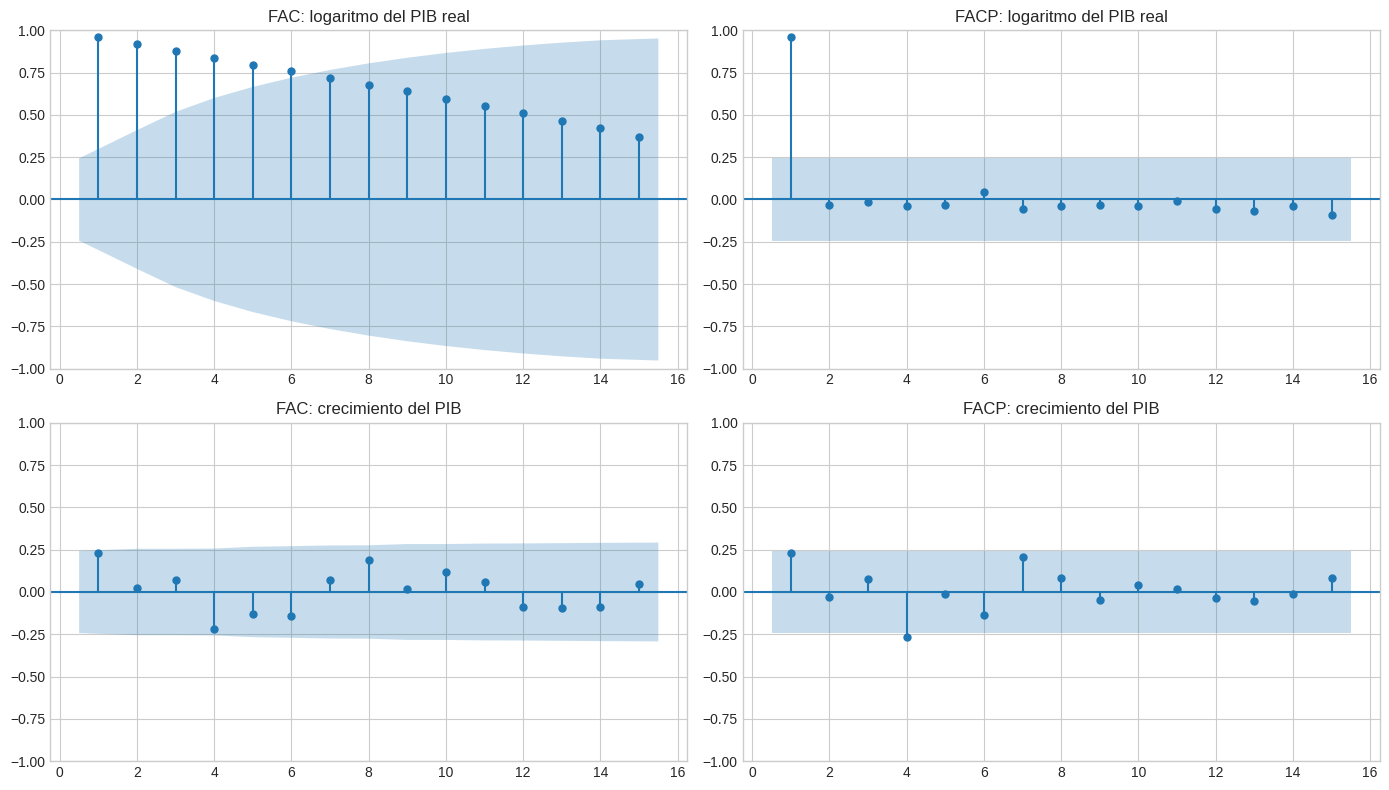

In [ ]:
# 8. FAC y FACP del nivel y del crecimiento
serie_nivel = datos['log_pib'].dropna()
serie_crecimiento = datos['crecimiento_pib'].dropna()
max_lags = min(15, len(serie_crecimiento) // 2 - 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf(serie_nivel, lags=max_lags, ax=axes[0, 0], zero=False)
axes[0, 0].set_title('FAC: logaritmo del PIB real')

plot_pacf(
    serie_nivel,
    lags=max_lags,
    ax=axes[0, 1],
    zero=False,
    method='ywm',
)
axes[0, 1].set_title('FACP: logaritmo del PIB real')

plot_acf(serie_crecimiento, lags=max_lags, ax=axes[1, 0], zero=False)
axes[1, 0].set_title('FAC: crecimiento del PIB')

plot_pacf(
    serie_crecimiento,
    lags=max_lags,
    ax=axes[1, 1],
    zero=False,
    method='ywm',
)
axes[1, 1].set_title('FACP: crecimiento del PIB')

plt.tight_layout()
plt.show()

**Interpretación** (valores aproximados, leídos de los gráficos):

| Serie | Rezago 1 | Rezago 2 | Rezago 3 |
|---|---|---|---|
| FAC log(PIB) | ≈ 0,96 | ≈ 0,92 | ≈ 0,88 |
| FACP log(PIB) | ≈ 0,96 | ≈ −0,03 | ≈ −0,01 |
| FAC crecimiento | ≈ 0,23 | ≈ 0,02 | ≈ 0,07 |
| FACP crecimiento | ≈ 0,23 | ≈ −0,03 | ≈ 0,08 |

- **log(PIB):** la FAC es muy alta en los tres rezagos, fuera de las bandas, y decae lentamente. El PIB de un año está muy relacionado con el de los años anteriores. La FACP solo es significativa en el rezago 1 (≈ 0,96) y después se corta, porque la relación con los rezagos 2 y 3 se explica completamente a través del rezago 1. Este patrón es típico de una **raíz unitaria** ($X_t \approx X_{t-1} + \varepsilon_t$): el nivel **no es estacionario**.
- **Crecimiento:** en la FAC y en la FACP, el rezago 1 (≈ 0,23) queda en el borde de la banda y los rezagos 2 y 3 son cercanos a cero, dentro de las bandas. Hay una **dependencia positiva débil** con el año anterior y prácticamente ninguna con años más lejanos: un año de alto crecimiento no implica que el siguiente también lo sea. El patrón es compatible con una serie **estacionaria** de baja persistencia.

### 4. Contraste ADF y KPSS.

In [ ]:
# 10. ADF y KPSS
adf_nivel = adfuller(serie_nivel, regression='ct', autolag='AIC')
kpss_nivel = kpss(serie_nivel, regression='ct', nlags='auto')

adf_crecimiento = adfuller(serie_crecimiento, regression='c', autolag='AIC')
kpss_crecimiento = kpss(serie_crecimiento, regression='c', nlags='auto')

pruebas = pd.DataFrame(
    {
        'ADF estadístico': [adf_nivel[0], adf_crecimiento[0]],
        'ADF p': [adf_nivel[1], adf_crecimiento[1]],
        'KPSS estadístico': [kpss_nivel[0], kpss_crecimiento[0]],
        'KPSS p': [kpss_nivel[1], kpss_crecimiento[1]],
    },
    index=['log(PIB real)', 'crecimiento del PIB'],
)

print(pruebas.round(4))
print('\nRegla con 5%:')
print('- ADF p < 0,05: rechazar raíz unitaria.')
print('- KPSS p < 0,05: rechazar estacionariedad.')

                     ADF estadístico  ADF p  KPSS estadístico  KPSS p
log(PIB real)                 -1.938  0.635             0.166   0.034
crecimiento del PIB           -6.243  0.000             0.105   0.100

Regla con 5%:
- ADF p < 0,05: rechazar raíz unitaria.
- KPSS p < 0,05: rechazar estacionariedad.


/tmp/ipykernel_1179/1888993785.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_nivel = adfuller(serie_nivel, regression='ct', autolag='AIC')
/tmp/ipykernel_1179/1888993785.py:3: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_nivel = kpss(serie_nivel, regression='ct', nlags='auto')
/tmp/ipykernel_1179/1888993785.py:5: Futu

**Interpretación** (regla al 5%):

| Serie | ADF p | KPSS p | Lectura conjunta |
|---|---|---|---|
| log(PIB real) | 0,635 → no rechaza raíz unitaria | 0,034 → rechaza estacionariedad | **No estacionaria** |
| Crecimiento del PIB | 0,000 → rechaza raíz unitaria | 0,100 → no rechaza estacionariedad | **Estacionaria** |

- **log(PIB):** la ADF no rechaza la hipótesis de raíz unitaria (p = 0,635 > 0,05) y la KPSS rechaza la hipótesis de estacionariedad (p = 0,034 < 0,05). Las dos pruebas coinciden: **el nivel no es estacionario**.
- **Crecimiento:** la ADF rechaza la raíz unitaria (p ≈ 0,000; estadístico −6,243, muy negativo) y la KPSS no rechaza la estacionariedad (p = 0,100). Las dos pruebas coinciden: **el crecimiento es estacionario**.
- Los avisos `FutureWarning` e `InterpolationWarning` no son errores. El segundo indica que el valor p real de la KPSS del crecimiento es **mayor** que 0,100, lo que refuerza la conclusión.

Las pruebas confirman lo que mostraban los gráficos, las estadísticas móviles y la FAC.

### 5. Redacte una conclusión de máximo 150 palabras.

*(Usando la plantilla de la sección 14.)*

> La serie en nivel presenta una tendencia creciente persistente, por lo que la media parece no constante. La FAC muestra autocorrelaciones cercanas a 0,96 que decaen lentamente, y la FACP solo destaca en el rezago 1, patrón típico de raíz unitaria. Las pruebas ADF y KPSS entregan evidencia coincidente de no estacionariedad en el nivel (ADF p = 0,635; KPSS p = 0,034). Después de aplicar logaritmo y primera diferencia, es decir, trabajar con el crecimiento, la serie muestra una media estable cercana a 4%, autocorrelaciones pequeñas y pruebas favorables a la estacionariedad (ADF p ≈ 0; KPSS p ≥ 0,10). Por tanto, para el modelamiento posterior se recomienda usar el crecimiento del PIB y no su nivel. Esta conclusión debe complementarse con la revisión de quiebres, atípicos y contexto económico, como las crisis de 1975, 1982 y 2020.

*(139 palabras.)*

## Actividad 3: cambiar país (Perú)

**Pasos:**
1. Guardar un resumen de los resultados de Chile, antes de que la descarga del otro país reemplace la tabla `datos`.
2. Repetir las celdas de las secciones 4 a 11 cambiando `CHL` por `PER` en **las dos URL** y "Chile" por "Perú" en los títulos.
3. Resumir los resultados de Perú y compararlos con Chile en una tabla (celdas nuevas).

Para usar otro país, cambia `PER` por `ARG`, `COL`, `MEX` o `BRA` en las dos URL de la descarga.

In [ ]:
# Resumen de Chile, antes de descargar otro país
resumen_chile = {
    'Primer año': str(datos.index.min()),
    'Último año': str(datos.index.max()),
    'Años disponibles': str(len(datos)),
    'Crecimiento promedio (%)': round(datos['crecimiento_pib'].mean(), 3),
    'Desv. estándar del crecimiento': round(datos['crecimiento_pib'].std(), 3),
    'Desv. estándar hasta 1990': round(datos.loc[:1990, 'crecimiento_pib'].std(), 3),
    'Desv. estándar desde 1991': round(datos.loc[1991:, 'crecimiento_pib'].std(), 3),
    'Año de mayor caída': str(datos['crecimiento_pib'].idxmin()),
    'Mayor caída (%)': round(datos['crecimiento_pib'].min(), 3),
    'Año de mayor alza': str(datos['crecimiento_pib'].idxmax()),
    'Mayor alza (%)': round(datos['crecimiento_pib'].max(), 3),
    'ADF p nivel': round(adf_nivel[1], 4),
    'KPSS p nivel': round(kpss_nivel[1], 4),
    'ADF p crecimiento': round(adf_crecimiento[1], 4),
    'KPSS p crecimiento': round(kpss_crecimiento[1], 4),
}

print(pd.Series(resumen_chile, dtype=object))

### Descarga y análisis de Perú

In [ ]:
# 3. Serie 1: PIB real de Perú, nivel
url_nivel = 'https://api.worldbank.org/v2/country/PER/indicator/NY.GDP.MKTP.KD'
params_nivel = {
    'format': 'json',
    'date': '1960:2030',
    'per_page': 200,
}

respuesta_nivel = requests.get(url_nivel, params=params_nivel, timeout=60)
respuesta_nivel.raise_for_status()
json_nivel = respuesta_nivel.json()

if not isinstance(json_nivel, list) or len(json_nivel) < 2 or json_nivel[1] is None:
    raise RuntimeError('La API no devolvió el PIB real de Perú.')

datos_nivel = pd.DataFrame(json_nivel[1])[['date', 'value']]
datos_nivel.columns = ['anio', 'pib_real']
datos_nivel['anio'] = pd.to_numeric(datos_nivel['anio'], errors='coerce')
datos_nivel['pib_real'] = pd.to_numeric(datos_nivel['pib_real'], errors='coerce')
datos_nivel = datos_nivel.dropna().sort_values('anio')

# 4. Serie 2: crecimiento anual del PIB real
url_crecimiento = 'https://api.worldbank.org/v2/country/PER/indicator/NY.GDP.MKTP.KD.ZG'
params_crecimiento = {
    'format': 'json',
    'date': '1960:2030',
    'per_page': 200,
}

respuesta_crecimiento = requests.get(
    url_crecimiento,
    params=params_crecimiento,
    timeout=60,
)
respuesta_crecimiento.raise_for_status()
json_crecimiento = respuesta_crecimiento.json()

if not isinstance(json_crecimiento, list) or len(json_crecimiento) < 2 or json_crecimiento[1] is None:
    raise RuntimeError('La API no devolvió el crecimiento del PIB de Perú.')

datos_crecimiento = pd.DataFrame(json_crecimiento[1])[['date', 'value']]
datos_crecimiento.columns = ['anio', 'crecimiento_pib']
datos_crecimiento['anio'] = pd.to_numeric(datos_crecimiento['anio'], errors='coerce')
datos_crecimiento['crecimiento_pib'] = pd.to_numeric(
    datos_crecimiento['crecimiento_pib'],
    errors='coerce',
)
datos_crecimiento = datos_crecimiento.dropna().sort_values('anio')

datos = pd.merge(datos_nivel, datos_crecimiento, on='anio', how='inner')
datos = datos.set_index('anio')

print('Primera observación:', datos.index.min())
print('Última observación:', datos.index.max())
print('Número de años:', len(datos))
print(datos.tail())

In [ ]:
# 5. Gráficos de las series originales
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(datos.index, datos['pib_real'] / 1e9, color='#123047', linewidth=2)
axes[0].set_title('Perú: PIB real')
axes[0].set_ylabel('Miles de millones de US$ de 2015')

axes[1].plot(datos.index, datos['crecimiento_pib'], color='#E67E22', linewidth=2)
axes[1].axhline(0, color='#5D6B75', linewidth=1)
axes[1].set_title('Perú: crecimiento anual del PIB real')
axes[1].set_xlabel('Año')
axes[1].set_ylabel('Porcentaje')

plt.tight_layout()
plt.show()

In [ ]:
# 6. Estadísticas móviles de diez años
ventana = 10

datos['media_movil_nivel'] = datos['pib_real'].rolling(ventana).mean()
datos['var_movil_nivel'] = datos['pib_real'].rolling(ventana).var()
datos['media_movil_crecimiento'] = datos['crecimiento_pib'].rolling(ventana).mean()
datos['var_movil_crecimiento'] = datos['crecimiento_pib'].rolling(ventana).var()

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

axes[0, 0].plot(datos.index, datos['pib_real'] / 1e9, color='#AEB9C0')
axes[0, 0].plot(datos.index, datos['media_movil_nivel'] / 1e9, color='#123047')
axes[0, 0].set_title('PIB real y media móvil')

axes[0, 1].plot(datos.index, datos['var_movil_nivel'] / 1e18, color='#C84A4A')
axes[0, 1].set_title('Varianza móvil del PIB real')

axes[1, 0].plot(datos.index, datos['crecimiento_pib'], color='#F2B879')
axes[1, 0].plot(datos.index, datos['media_movil_crecimiento'], color='#E67E22')
axes[1, 0].set_title('Crecimiento y media móvil')

axes[1, 1].plot(datos.index, datos['var_movil_crecimiento'], color='#2D8C72')
axes[1, 1].set_title('Varianza móvil del crecimiento')

plt.tight_layout()
plt.show()

In [ ]:
# 7. Logaritmo y primera diferencia logarítmica
datos['log_pib'] = np.log(datos['pib_real'])
datos['crecimiento_log'] = 100 * datos['log_pib'].diff()

comparacion_crecimiento = datos[
    ['crecimiento_pib', 'crecimiento_log']
].dropna()

correlacion_crecimientos = comparacion_crecimiento.corr().iloc[0, 1]

print('Correlación entre ambas medidas:', round(correlacion_crecimientos, 4))
print(comparacion_crecimiento.tail().round(3))

plt.figure(figsize=(12, 5))
plt.plot(
    comparacion_crecimiento.index,
    comparacion_crecimiento['crecimiento_pib'],
    label='Crecimiento publicado',
    color='#123047',
)
plt.plot(
    comparacion_crecimiento.index,
    comparacion_crecimiento['crecimiento_log'],
    label='100 × diferencia logarítmica',
    color='#E67E22',
    linestyle='--',
)
plt.axhline(0, color='#5D6B75', linewidth=1)
plt.title('Dos formas de representar el crecimiento real')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 8. FAC y FACP del nivel y del crecimiento
serie_nivel = datos['log_pib'].dropna()
serie_crecimiento = datos['crecimiento_pib'].dropna()
max_lags = min(15, len(serie_crecimiento) // 2 - 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf(serie_nivel, lags=max_lags, ax=axes[0, 0], zero=False)
axes[0, 0].set_title('FAC: logaritmo del PIB real')

plot_pacf(
    serie_nivel,
    lags=max_lags,
    ax=axes[0, 1],
    zero=False,
    method='ywm',
)
axes[0, 1].set_title('FACP: logaritmo del PIB real')

plot_acf(serie_crecimiento, lags=max_lags, ax=axes[1, 0], zero=False)
axes[1, 0].set_title('FAC: crecimiento del PIB')

plot_pacf(
    serie_crecimiento,
    lags=max_lags,
    ax=axes[1, 1],
    zero=False,
    method='ywm',
)
axes[1, 1].set_title('FACP: crecimiento del PIB')

plt.tight_layout()
plt.show()

In [ ]:
# 10. ADF y KPSS
adf_nivel = adfuller(serie_nivel, regression='ct', autolag='AIC')
kpss_nivel = kpss(serie_nivel, regression='ct', nlags='auto')

adf_crecimiento = adfuller(serie_crecimiento, regression='c', autolag='AIC')
kpss_crecimiento = kpss(serie_crecimiento, regression='c', nlags='auto')

pruebas = pd.DataFrame(
    {
        'ADF estadístico': [adf_nivel[0], adf_crecimiento[0]],
        'ADF p': [adf_nivel[1], adf_crecimiento[1]],
        'KPSS estadístico': [kpss_nivel[0], kpss_crecimiento[0]],
        'KPSS p': [kpss_nivel[1], kpss_crecimiento[1]],
    },
    index=['log(PIB real)', 'crecimiento del PIB'],
)

print(pruebas.round(4))
print('\nRegla con 5%:')
print('- ADF p < 0,05: rechazar raíz unitaria.')
print('- KPSS p < 0,05: rechazar estacionariedad.')

### Tabla comparativa Chile vs Perú

In [ ]:
# Resumen de Perú y comparación con Chile
resumen_peru = {
    'Primer año': str(datos.index.min()),
    'Último año': str(datos.index.max()),
    'Años disponibles': str(len(datos)),
    'Crecimiento promedio (%)': round(datos['crecimiento_pib'].mean(), 3),
    'Desv. estándar del crecimiento': round(datos['crecimiento_pib'].std(), 3),
    'Desv. estándar hasta 1990': round(datos.loc[:1990, 'crecimiento_pib'].std(), 3),
    'Desv. estándar desde 1991': round(datos.loc[1991:, 'crecimiento_pib'].std(), 3),
    'Año de mayor caída': str(datos['crecimiento_pib'].idxmin()),
    'Mayor caída (%)': round(datos['crecimiento_pib'].min(), 3),
    'Año de mayor alza': str(datos['crecimiento_pib'].idxmax()),
    'Mayor alza (%)': round(datos['crecimiento_pib'].max(), 3),
    'ADF p nivel': round(adf_nivel[1], 4),
    'KPSS p nivel': round(kpss_nivel[1], 4),
    'ADF p crecimiento': round(adf_crecimiento[1], 4),
    'KPSS p crecimiento': round(kpss_crecimiento[1], 4),
}

comparacion_paises = pd.DataFrame(
    {'Chile': resumen_chile, 'Perú': resumen_peru},
    dtype=object,
)
print(comparacion_paises)

print('\nCinco menores tasas de crecimiento de Perú:')
print(datos['crecimiento_pib'].nsmallest(5).round(2))
print('\nCinco mayores tasas de crecimiento de Perú:')
print(datos['crecimiento_pib'].nlargest(5).round(2))

In [ ]:
# Lectura conjunta de ADF y KPSS (tabla de la sección 11)
def lectura_conjunta(adf_p, kpss_p):
    if adf_p < 0.05 and kpss_p >= 0.05:
        return 'estacionaria'
    if adf_p >= 0.05 and kpss_p < 0.05:
        return 'no estacionaria'
    if adf_p < 0.05 and kpss_p < 0.05:
        return 'resultado conflictivo: revisar quiebres'
    return 'evidencia insuficiente'


for pais, r in [('Chile', resumen_chile), ('Perú', resumen_peru)]:
    print(pais)
    print('  Nivel (log PIB):', lectura_conjunta(r['ADF p nivel'], r['KPSS p nivel']))
    print('  Crecimiento:    ', lectura_conjunta(r['ADF p crecimiento'], r['KPSS p crecimiento']))

### Interpretación de la comparación

Al ejecutar las celdas anteriores, la tabla entrega los valores exactos de Perú. Así se interpreta cada punto:

**1. Años disponibles**
- Chile: 1961–2025, **65 años**.
- Perú: filas `Primer año`, `Último año` y `Años disponibles`. Si el período es el mismo, la comparación es directa. Si Perú tiene menos años, las pruebas y la FAC usan menos datos y son menos precisas, y las bandas de confianza de la FAC serán más anchas.

**2. Volatilidad del crecimiento**
- Se compara con la `Desv. estándar del crecimiento` (mayor desviación = crecimiento más volátil) y con el gráfico de **varianza móvil del crecimiento**.
- En Chile la volatilidad fue alta hasta comienzos de los 90 y baja después. Compara las filas `Desv. estándar hasta 1990` y `desde 1991`: si en Perú la primera es mucho mayor que la segunda, Perú también tuvo un período inicial inestable y luego se estabilizó.
- Conclusión: el país con mayor desviación estándar tuvo un crecimiento más volátil.

**3. Resultados ADF y KPSS**
- La última celda aplica la tabla de la sección 11 a ambos países.
- En Chile: **nivel no estacionario y crecimiento estacionario**.
- Si en Perú se obtiene lo mismo, la conclusión se mantiene: hay que trabajar con el crecimiento y no con el nivel.
- Si aparece un *resultado conflictivo* o *evidencia insuficiente*, se debe probablemente a **quiebres** (crisis muy profundas) que afectan las pruebas. Como dice la clase, en ese caso hay que revisar quiebres y especificación.

**4. Forma de la FAC y la FACP**
- **Nivel:** en Chile la FAC parte cerca de 0,96 y decae lentamente, y la FACP tiene un solo pico en el rezago 1. Si Perú muestra el mismo patrón, su PIB también tiene **raíz unitaria**.
- **Crecimiento:** en Chile las barras son pequeñas y solo el rezago 1 (≈ 0,23) queda en el borde. Revisa si en Perú alguna barra sale claramente de la banda. Si el rezago 1 es significativo, un año de crisis tiende a seguirse de otro año malo (más persistencia que en Chile). Si todas quedan dentro, el crecimiento de Perú también tiene baja dependencia.

**5. Observaciones extremas y posibles quiebres**
- Chile: caídas en **1975 (≈ −12%)**, **1982 (≈ −11%)** y **2020 (≈ −6%)**, y rebote en **2021 (≈ +11%)**. Hay un quiebre en la volatilidad a comienzos de los 90.
- Perú: las listas de las cinco menores y cinco mayores tasas muestran sus años extremos. Al revisarlas, ten en cuenta episodios conocidos de la economía peruana: la crisis de **1983**, la hiperinflación de **1988-1990**, la pandemia de **2020** y el rebote de **2021**. Si varios años negativos aparecen seguidos, como 1988-1990, son un **quiebre prolongado** y no un atípico aislado. Si el gráfico de crecimiento cambia de comportamiento antes y después de ese período, hay un cambio de régimen.

**Conclusión general:** en ambos países se espera que el **PIB en nivel no sea estacionario** y que **su crecimiento sí lo sea**, por lo que se modela el crecimiento. Las diferencias entre países están en la **volatilidad** y en las **crisis**: el país con crisis más profundas o seguidas presenta más valores extremos, mayor varianza móvil y posibles quiebres que deben revisarse antes de modelar.